<a href="https://colab.research.google.com/github/smir-nat/AK/blob/main/lab4/spam.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Практична робота 4**

Наївний байєсівський класифікатор в системах машинного навчання

Точність (Accuracy): 0.9839

Звіт класифікації:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99       965
           1       0.99      0.89      0.94       150

    accuracy                           0.98      1115
   macro avg       0.98      0.95      0.96      1115
weighted avg       0.98      0.98      0.98      1115



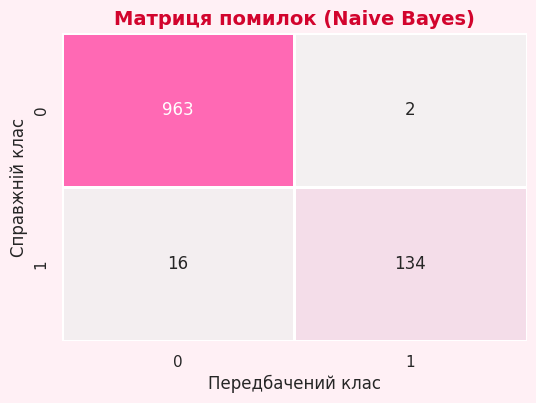

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

sns.set_theme(style="whitegrid", rc={"axes.facecolor": "#FFF0F5", "figure.facecolor": "#FFF0F5", "axes.edgecolor": "#FFB6C1"})

df = pd.read_csv('https://raw.githubusercontent.com/smir-nat/AK/main/lab4/spam.csv', encoding='latin-1')
df = df[['v1', 'v2']]
df.columns = ['label', 'text']
df['label'] = df['label'].map({'ham': 0, 'spam': 1})

X_train, X_test, y_train, y_test = train_test_split(df['text'], df['label'], test_size=0.2, random_state=42)

vectorizer = CountVectorizer()
X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

nb_classifier = MultinomialNB(alpha=1.0)
nb_classifier.fit(X_train_vec, y_train)

y_pred = nb_classifier.predict(X_test_vec)

accuracy = accuracy_score(y_test, y_pred)
print(f"Точність (Accuracy): {accuracy:.4f}\n")
print("Звіт класифікації:")
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap=sns.light_palette("#FF69B4", as_cmap=True),
            cbar=False, linewidths=2, linecolor='white')
plt.title('Матриця помилок (Naive Bayes)', fontsize=14, fontweight='bold', color='#D2042D')
plt.xlabel('Передбачений клас', fontsize=12)
plt.ylabel('Справжній клас', fontsize=12)
plt.show()